# Praktikum 2: Support Vector Regression (SVR)

Memprediksi gaji berdasarkan tingkat posisi menggunakan SVR dengan kernel RBF, mengacu pada langkah-langkah modul. Dataset yang digunakan adalah `Posisi_gaji.csv`.

### 1. Mengimpor Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

### 2. Mengimpor Dataset

Kolom `Level` digunakan sebagai fitur X dan kolom `Gaji` sebagai target y. Simpan data asli agar grafik dan prediksi dapat ditampilkan dalam satuan semula.

In [2]:
# Mendukung eksekusi dari folder Pertemuan_7 maupun root proyek.
dataset_path = Path('Posisi_gaji.csv')
if not dataset_path.is_file():
    dataset_path = Path('Pertemuan_7') / 'Posisi_gaji.csv'

dataset = pd.read_csv(dataset_path)
X_asli = dataset.iloc[:, 1:2].to_numpy()
y_asli = dataset.iloc[:, 2].to_numpy()

dataset

,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


### 3. Feature Scaling

Gunakan scaler terpisah untuk fitur dan target. `StandardScaler` menerima array dua dimensi, sedangkan `SVR.fit` memerlukan target satu dimensi. Karena itu, hasil standardisasi target diubah menjadi satu dimensi dengan `ravel()`.

In [3]:
from sklearn.preprocessing import StandardScaler

sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X_asli)
y = sc_y.fit_transform(y_asli.reshape(-1, 1)).ravel()

pd.DataFrame({'Level (standar)': X.ravel(), 'Gaji (standar)': y})

,Level (standar),Gaji (standar)
0,-1.566699,-0.720043
1,-1.218544,-0.702438
2,-0.870388,-0.667228
3,-0.522233,-0.596808
4,-0.174078,-0.491178
5,0.174078,-0.350339
6,0.522233,-0.174289
7,0.870388,0.177810
8,1.218544,0.882008
9,1.566699,2.642503


### 4. Fitting SVR ke Dataset

Sesuai modul, model dilatih menggunakan seluruh dataset yang sudah distandardisasi, dengan kernel RBF dan parameter SVR lainnya menggunakan nilai bawaan.

In [4]:
from sklearn.svm import SVR

regressor = SVR(kernel='rbf')
regressor.fit(X, y)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


### 5. Visualisasi Hasil SVR

Buat grid tingkat posisi dengan interval 0,01 agar kurva halus. Grid ditransformasikan sebelum prediksi, lalu hasil prediksi dikembalikan ke skala gaji asli. Titik merah menunjukkan data asli dan garis biru menunjukkan prediksi model.

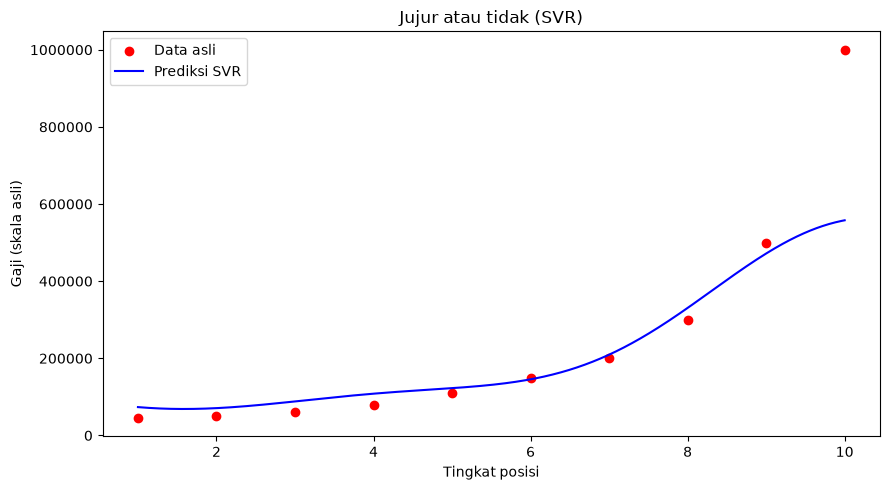

In [5]:
# Batas grid berupa nilai skalar, bukan array satu elemen.
X_grid = np.arange(X_asli.min(), X_asli.max() + 0.005, 0.01).reshape(-1, 1)
X_grid_scaled = sc_X.transform(X_grid)
y_grid_scaled = regressor.predict(X_grid_scaled)
y_grid = sc_y.inverse_transform(y_grid_scaled.reshape(-1, 1)).ravel()

plt.figure(figsize=(9, 5))
plt.scatter(X_asli.ravel(), y_asli, color='red', label='Data asli')
plt.plot(X_grid.ravel(), y_grid, color='blue', label='Prediksi SVR')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji (skala asli)')
plt.ticklabel_format(style='plain', axis='y')
plt.legend()
plt.tight_layout()
plt.show()

### 6. Prediksi Hasil

Prediksi gaji untuk tingkat posisi 6,5. Gunakan scaler yang telah dilatih pada langkah 3, tanpa melakukan `fit` ulang.

In [6]:
tingkat_posisi_prediksi = np.array([[6.5]])
tingkat_posisi_scaled = sc_X.transform(tingkat_posisi_prediksi)
gaji_prediksi_scaled = regressor.predict(tingkat_posisi_scaled)
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi_scaled.reshape(-1, 1))

### 7. Menampilkan Hasil

In [7]:
print(f'Prediksi Gaji untuk Tingkat Posisi 6.5: {gaji_prediksi[0, 0]:.2f}')

Prediksi Gaji untuk Tingkat Posisi 6.5: 170370.02


### 8. Validasi Hasil

Dengan dataset dan parameter yang sama, prediksi seharusnya mendekati **170370,02**, sesuai contoh modul. Sel berikut membandingkan hasil perhitungan dengan nilai referensi tersebut.

In [8]:
nilai_referensi_modul = 170370.0204065
sesuai_modul = np.isclose(gaji_prediksi[0, 0], nilai_referensi_modul, rtol=0, atol=0.01)
print(f'Nilai referensi modul: {nilai_referensi_modul:.2f}')
print(f'Sesuai modul (toleransi 0.01): {sesuai_modul}')

Nilai referensi modul: 170370.02
Sesuai modul (toleransi 0.01): True


### 9. Evaluasi Model SVR

Hitung MAE, MSE, RMSE, dan R-squared pada **skala standar**, mengikuti contoh modul. MAE dan RMSE berikut bukan dalam satuan gaji asli. Evaluasi menggunakan data yang sama dengan data pelatihan, sehingga hasil ini menunjukkan kecocokan pada data latih dan belum mengukur kinerja pada data baru.

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print('Evaluasi data latih pada skala standar')
print('MAE:', mae)
print('MSE:', mse)
print('RMSE:', rmse)
print('R-squared:', r2)

Evaluasi data latih pada skala standar
MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


Model SVR membentuk kurva nonlinier untuk hubungan tingkat posisi dan gaji. Prediksi tingkat posisi 6,5 ditampilkan dalam skala gaji asli, sedangkan metrik evaluasi memakai skala standar agar dapat dibandingkan langsung dengan keluaran modul.